<a href="https://colab.research.google.com/github/alexsandrox/jornada-ia-90-dias/blob/main/dia10_csv_limpeza_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dia 10: CSV, limpeza de dados e primeira análise exploratória (2h30)

Arquivo no Colab/GitHub: dia10_csv_limpeza_eda.ipynb

Até agora você criou os dados à mão. Hoje você trabalha com dados reais: carrega um arquivo CSV, descobre os problemas dele, limpa e extrai as primeiras conclusões. É o que se faz em qualquer projeto de IA, e a base do projeto da semana.

Meta de hoje: carregar um CSV, inspecionar, tratar dados faltantes e duplicados, converter tipos e responder perguntas com groupby.

## Exercício 1 — Extra
### Criação, inspeção e seleção de colunas

Crie um DataFrame chamado vendas com 4 linhas usando um dicionário de listas, contendo as colunas:

- "vendedor" (textos à sua escolha)
- "meta" (valores numéricos)
- "realizado" (valores numéricos)

Em seguida:

Exiba as dimensões da tabela (linhas e colunas) usando .shape.

Mostre na tela apenas as colunas "vendedor" e "realizado" juntas (lembre-se dos colchetes duplos para retornar uma tabela).

In [ ]:
import pandas as pd

# Exercício 1 - Extra
vendas = pd.DataFrame({
    "vendedor": ["Alex", "Gladys", "Andrade", "Teixeira"],
    "meta": [90, 80, 30, 55],
    "realizado": [10, 20, 70, 45]
})

print(vendas.shape)

print()
print(vendas[["vendedor", "realizado"]])

(4, 3)

   vendedor  realizado
0      Alex         10
1    Gladys         20
2   Andrade         70
3  Teixeira         45


Para destravar a lógica por trás dos colchetes duplos:
- Os colchetes de fora vendas[ ... ] são o comando de filtro/seleção do pandas.

- Os colchetes de dentro ["vendedor", "realizado"] criam a lista com as colunas que você quer puxar.

## Exercício 2 — Extra
### Coluna calculada e busca pelo maior valor (.idxmax())

Usando o mesmo DataFrame vendas do exercício anterior:

- Crie uma nova coluna chamada "diferenca" que seja o resultado de realizado - meta.
- Descubra o índice da linha com a maior "diferenca" usando .idxmax() e exiba os dados completos desse vendedor usando .loc[].

In [ ]:
# Exercício 2 - Extra
vendas["diferenca"] = vendas["realizado"] - vendas["meta"]
print(vendas["diferenca"])

maior_diferenca = vendas["diferenca"].idxmax()

print()
print(vendas.loc[maior_diferenca])

0   -80
1   -60
2    40
3   -10
Name: diferenca, dtype: int64

vendedor     Andrade
meta              30
realizado         70
diferenca         40
Name: 2, dtype: object


## Exercício 3 — Extra
### Filtro composto e ordenação
- Crie um DataFrame chamado estoque com 5 produtos contendo as colunas: "item", "setor", "preco" e "quantidade". Invente os valores, garantindo que haja pelo menos dois setores diferentes (ex: "Capacete", "Luva").
Em seguida:

- Filtre apenas os produtos de um setor específico E que tenham quantidade menor que 10.

- Ordene esse resultado filtrado pelo "preco", do maior para o menor.

In [ ]:
# Estoque
import pandas as pd

estoque = pd.DataFrame({
    "item": [
        "Capacete Race Tech Android",
        "Luva Mattos Racing ASX",
        "Bota Off-Road Alpinestars Tech 7",
        "Capacete ASW R3 Essence",
        "Luva IMS Pro"
    ],
    "setor": ["Capacetes", "Luvas", "Botas", "Capacetes", "Luvas"],
    "preco": [429.99, 169.54, 4199.50, 549.90, 129.90],
    "quantidade": [4, 16, 3, 2, 8]
})

# 1. Monta o filtro composto (cada condição dentro de seus próprios parênteses)
filtro = (estoque["setor"] == "Capacetes") & (estoque["quantidade"] < 10)

# 2. Aplica o filtro na tabela e já ordena pelo preço do maior para o menor
resultado = estoque[filtro].sort_values("preco", ascending=False)

print(resultado)


                         item      setor   preco  quantidade
3     Capacete ASW R3 Essence  Capacetes  549.90           2
0  Capacete Race Tech Android  Capacetes  429.99           4


## Exercício 4 — Extra

### Agrupamento com múltiplas métricas (.groupby() + .agg())

O método .agg() (abreviação de aggregate) resume dados aplicando uma ou mais funções de agregação — como soma (sum), média (mean), mínimo (min), máximo (max) ou contagem (count) — sobre um eixo do DataFrame (por coluna ou por linha) ou sobre grupos criados com .groupby().

### Ainda com o DataFrame estoque do Exercício 3:

- Agrupe os dados por "setor" e calcule ao mesmo tempo a média ("mean"), o valor máximo ("max") e a contagem ("count") da coluna "preco".

- Arredonde o resultado para 2 casas decimais.

In [ ]:
# Exercício 4
# agrupar, média, máximo, contagem

# 1. Agrupa por "setor"
# 2. Seleciona a coluna "preco"
# 3. Aplica as 3 métricas de uma vez com .agg() e arredonda para 2 casas
resumo_setor = estoque.groupby("setor")["preco"].agg(["mean", "max", "count"]).round(2)

print(resumo_setor)


              mean      max  count
setor                             
Botas      4199.50  4199.50      1
Capacetes   489.94   549.90      2
Luvas       149.72   169.54      2


## Exercício 5 — Extra

Diagnóstico e tratamento de dados faltantes (None / NaN)

- Crie um DataFrame chamado clientes com 4 linhas e as colunas "nome", "cidade" e "compras", colocando propositalmente None em uma célula de "cidade" e None em uma célula de "compras".
Em seguida:

- Exiba a contagem de valores faltantes por coluna usando .isna().sum().

- Crie um novo DataFrame chamado clientes_limpos substituindo os valores vazios por 0 com .fillna(0) e imprima o resultado.

In [ ]:
# Exercício 5
clientes = pd.DataFrame({
    "nome": ["Alex", "Ronaldo", "Maria", "Sebastiana"],
    "cidade": ["Mogi das Cruzes", "Belo Horizonte", "Recife", None],
    "compras": [5, None, 23, 12]
})

print(clientes.isna().sum())

print()
clientes_limpos = clientes.fillna(0)
print(clientes_limpos)

nome       0
cidade     1
compras    1
dtype: int64

         nome           cidade  compras
0        Alex  Mogi das Cruzes      5.0
1     Ronaldo   Belo Horizonte      0.0
2       Maria           Recife     23.0
3  Sebastiana                0     12.0


### 0:00 - 0:15 | Revisão ativa do Dia 9

Em um notebook novo, sem consultar nada:

- Crie um DataFrame com colunas nome e nota (4 alunos) e mostre só quem tem nota maior ou igual a 7.
- Crie uma coluna situacao que vale True se a nota for maior ou igual a 7.
- Previsão: o que df.iloc[0] devolve? E df.loc[0, "nome"]?

In [ ]:
# 1. Crie um DataFrame com colunas nome e nota (4 alunos) e mostre só quem tem nota maior ou igual a 7.
import pandas as pd

# 1. Cria o DataFrame com 4 alunos e suas notas
alunos = pd.DataFrame({
    "nome": ["Alex", "Leon", "Ashley", "Salazar"],
    "nota": [9.8, 6.0, 9.2, 5.0]
})

# 2. Filtra apenas quem tem nota maior ou igual a 7
aprovados = alunos[alunos["nota"] >= 7]
print(aprovados)


# 3. Crie uma coluna situacao que vale True se a nota for maior ou igual a 7.
print()
alunos["situacao"] = alunos["nota"] >= 7
print(alunos)

# 4. Previsão: o que df.iloc[0] devolve? E df.loc[0, "nome"]?
print()
print(alunos.iloc[0])  # Devolve a primeira linha inteira (posição 0) em formato de Series vertical
print(alunos.loc[0, "nome"])  # Devolve o valor exato que está no cruzamento da linha de índice 0 com a coluna "nome"


     nome  nota
0    Alex   9.8
2  Ashley   9.2

      nome  nota  situacao
0     Alex   9.8      True
1     Leon   6.0     False
2   Ashley   9.2      True
3  Salazar   5.0     False

nome        Alex
nota         9.8
situacao    True
Name: 0, dtype: object
Alex


### 0:15 - 0:30 | A ideia central

Todo projeto de dados segue um ciclo:

- Carregar o arquivo
- Inspecionar (formato, tipos, estatísticas)
- Limpar (faltantes, duplicados, tipos errados)
- Explorar (agrupar, comparar, visualizar)
- Concluir (responder perguntas)

Dados reais vêm sujos: células vazias, linhas repetidas, números salvos como texto. Quem limpa bem descobre mais, e modelos de IA treinados com dados sujos aprendem errado.

## 1. O ciclo profissional de análise de dados

1. **Definir o problema** — Qual pergunta precisamos responder? Qual decisão será tomada?

2. **Coletar e carregar** — De onde vêm os dados? CSV, Excel, API, banco de dados, etc.

3. **Inspecionar** — Estrutura, dimensões, tipos, qualidade e consistência.

4. **Validar** — Verificar se os dados realmente representam o que deveriam.

5. **Limpar e transformar** — Corrigir problemas, padronizar e preparar os dados.

6. **Explorar (EDA)** — Investigar padrões, distribuições, correlações e anomalias.

7. **Analisar e modelar** — Aplicar estatística, regras de negócio ou Machine Learning.

8. **Interpretar** — Separar fatos, correlações, hipóteses e conclusões.

9. **Comunicar** — Transformar resultados em informações que orientem decisões.

10. **Monitorar** — Verificar se os dados e resultados continuam confiáveis ao longo do tempo.

## 2. "Dados sujos" são mais perigosos do que parecem

A limpeza não é apenas corrigir erros visíveis. Existem vários tipos de problemas:

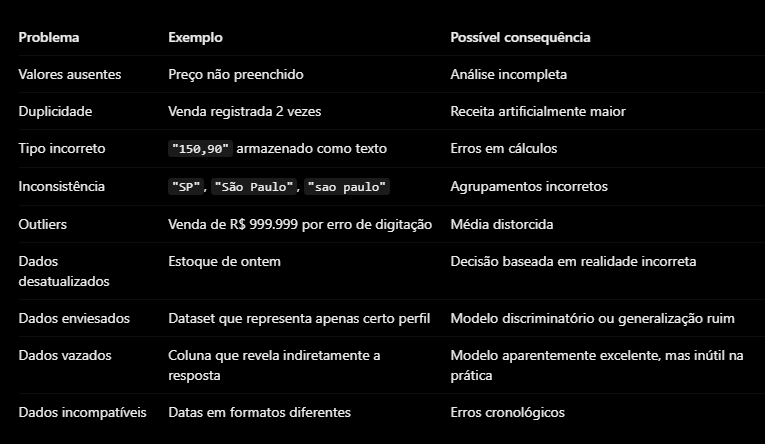

Um conceito que quero que você aprenda desde cedo
Nunca exclua um dado simplesmente porque ele parece estranho.

Uma venda de R$ 10.000 pode ser um erro, mas também pode ser uma venda legítima de um produto de alto valor.

### Antes de excluir, pergunte:

1. É um erro de registro?
2. É um evento legítimo e raro?
3. Esse dado é relevante para o problema?
4. A exclusão pode distorcer a análise?

Um analista ruim apaga o problema.
Um analista competente investiga o problema.

## 3. Limpar dados não significa manipular resultados
Isso é extremamente importante.

Imagine que você queira descobrir qual campanha publicitária foi mais lucrativa.

Você encontra três campanhas:
- Campanha A: ROAS 8
- Campanha B: ROAS 2
- Campanha C: ROAS 0,5

Se você simplesmente remover a campanha C porque ela "prejudica os resultados", estará manipulando a análise.

A limpeza precisa ser baseada em critérios técnicos justificáveis, nunca em critérios destinados a produzir uma conclusão desejada.

## 4. O perigo mais importante para Machine Learning: Data Leakage
Este conceito precisa entrar na nossa jornada.

Data Leakage (vazamento de dados) ocorre quando o modelo recebe, durante o treinamento, informações que não deveria conhecer no momento em que precisaria realizar uma previsão real.

Exemplo:

Você quer criar um modelo que prevê se um cliente comprará determinado produto.

Mas, no dataset, existe uma coluna chamada data_da_compra.

Se essa informação foi registrada depois da decisão de compra, o modelo pode aprender a utilizar informações do futuro.

Resultado:
- Durante o teste: 99% de acurácia.
- Na vida real: desempenho péssimo.
O modelo não ficou inteligente. Nós inadvertidamente entregamos a resposta a ele.

Isso é um dos motivos pelos quais a preparação dos dados é tão importante quanto a escolha do algoritmo.

## 5. Aprender a questionar os dados: pensamento crítico
Quando recebermos qualquer dataset, quero que você desenvolva o hábito de fazer estas perguntas:

Sobre a origem
- Quem gerou esses dados?
- De onde vieram?
- São confiáveis?
- Quando foram coletados?

Sobre a estrutura
- Cada linha representa o quê?
- Cada coluna representa o quê?
- Existem identificadores únicos?
- Existem dados duplicados?

Sobre a qualidade
- Há valores faltantes?
- Existem valores impossíveis?
- Existem inconsistências?
- Existem dados que parecem suspeitos?

Sobre a interpretação
- A média realmente representa os dados?
- Existe algum viés?
- Uma correlação está sendo confundida com causalidade?
- A conclusão é sustentada pelos dados?

Sobre o resultado
- Qual decisão esse resultado pode melhorar?
- Quais são as limitações?
- O que ainda não sabemos?

Esse raciocínio diferencia alguém que sabe executar Python de alguém que sabe analisar dados com Python.

## 6. O que você precisa dominar tecnicamente no Python
Essa afirmação do Claude também conecta diretamente com várias ferramentas que estudaremos:

### Python
- Linguagem para automatizar, manipular, analisar e construir aplicações.

### Pandas
- Manipulação de tabelas, datasets, filtros, agrupamentos, joins, limpeza e transformação.

### NumPy
- Operações numéricas, arrays, cálculos matemáticos e fundamentos computacionais.

### Matplotlib
- Visualização de dados, gráficos e análise visual.

### Scikit-learn
- Preparação de dados, Machine Learning, treinamento, validação e avaliação de modelos.

O checklist que quero que se torne automático.

Sempre que você receber um arquivo de dados, pense:

In [ ]:
df.shape
df.head()
df.tail()
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()
df.dtypes

Não é necessário decorar tudo de uma vez.

O objetivo é que, com a prática, você passe a inspecionar qualquer dataset naturalmente.

## 7. A habilidade que considero mais valiosa: transformar dados em decisões
Vamos usar um exemplo próximo do universo de e-commerce.

Imagine um arquivo com 100 mil pedidos. Um iniciante pode dizer:
"Consegui carregar o CSV e fazer um gráfico."

Um profissional consegue responder:
- Qual categoria tem maior margem de contribuição?
- Quais produtos estão vendendo, mas não gerando lucro?
- Qual canal possui o maior custo de aquisição?
- Qual é a taxa de conversão?
- Quais produtos apresentam risco de ruptura?
- Qual comportamento antecede uma compra?
- Qual é a probabilidade de um cliente voltar a comprar?
- Quanto poderíamos aumentar o investimento sem comprometer a rentabilidade?

O Python é o instrumento. A capacidade de formular perguntas relevantes e tomar decisões fundamentadas é o verdadeiro diferencial.



---



### 0:30 - 1:30 | Guia prático (digite tudo)
Bloco 1: criar um CSV para praticar

Para não depender de download hoje, crie o seu próprio arquivo sujo:

In [ ]:
import pandas as pd
import numpy as np

csv_texto = """id,nome,cidade,idade,salario,data_admissao
1,Ana,São Paulo,28,4500,2022-03-10
2,Leo,Rio de Janeiro,35,6200,2021-07-01
3,Bia,São Paulo,,3800,2023-01-15
4,Alex,Mogi das Cruzes,41,7100,2020-11-30
4,Alex,Mogi das Cruzes,41,7100,2020-11-30
5,Carla,Rio de Janeiro,29,,2022-09-05
6,Davi,Curitiba,52,8300,2019-05-20
7,Eva,São Paulo,33,500,2021-12-12
"""

with open("funcionarios.csv", "w", encoding="utf-8") as f:
    f.write(csv_texto)

Esse trecho grava o texto em um arquivo. Note que ele tem uma linha duplicada (id 4) e valores faltando (idade da Bia, salário da Carla).

### Bloco 2: carregar e inspecionar

In [ ]:
df = pd.read_csv("funcionarios.csv")

print(df.head())
print()

print(df.shape)
print()

df.info()
print()

print(df.describe())

   id  nome           cidade  idade  salario data_admissao
0   1   Ana        São Paulo   28.0   4500.0    2022-03-10
1   2   Leo   Rio de Janeiro   35.0   6200.0    2021-07-01
2   3   Bia        São Paulo    NaN   3800.0    2023-01-15
3   4  Alex  Mogi das Cruzes   41.0   7100.0    2020-11-30
4   4  Alex  Mogi das Cruzes   41.0   7100.0    2020-11-30

(8, 6)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             8 non-null      int64  
 1   nome           8 non-null      object 
 2   cidade         8 non-null      object 
 3   idade          7 non-null      float64
 4   salario        7 non-null      float64
 5   data_admissao  8 non-null      object 
dtypes: float64(2), int64(1), object(3)
memory usage: 516.0+ bytes

         id      idade      salario
count  8.00   7.000000     7.000000
mean   4.00  37.000000  5357.142857
std    2.

Olhe o info(): a coluna idade virou float por causa do valor faltante, e data_admissao é texto (object).

### Bloco 3: encontrar problemas

In [ ]:
# faltantes por coluna
print(df.isna().sum())
print()

# linhas duplicadas
print(df.duplicated().sum())
print()

# quais são
print(df[df.duplicated()])


id               0
nome             0
cidade           0
idade            1
salario          1
data_admissao    0
dtype: int64

1

   id  nome           cidade  idade  salario data_admissao
4   4  Alex  Mogi das Cruzes   41.0   7100.0    2020-11-30


### Bloco 4: remover duplicados

In [ ]:
df = df.drop_duplicates()
print(df.shape)

(7, 6)


Confira que passou de 8 para 7 linhas.

### Bloco 5: tratar faltantes

In [ ]:
# opção 1: preencher com a mediana
df["idade"] = df["idade"].fillna(df["idade"].median())

# opção 2: preencher com a média
df["salario"] = df["salario"].fillna(df["salario"].mean())

print(df.isna().sum())

id               0
nome             0
cidade           0
idade            0
salario          0
data_admissao    0
dtype: int64


Não existe regra única: **remover** perde dados, **preencher** inventa dados. A escolha depende do problema, e deve ser uma decisão consciente (lembra do numero_de_caracteres do Dia 6?).

### Bloco 6: converter tipos

In [ ]:
df["idade"] = df["idade"].astype(int)
df["data_admissao"] = pd.to_datetime(df["data_admissao"])

df.info()
print(df["data_admissao"].dt.year)

<class 'pandas.core.frame.DataFrame'>
Index: 7 entries, 0 to 7
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             7 non-null      int64         
 1   nome           7 non-null      object        
 2   cidade         7 non-null      object        
 3   idade          7 non-null      int64         
 4   salario        7 non-null      float64       
 5   data_admissao  7 non-null      datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(2), object(2)
memory usage: 392.0+ bytes
0    2022
1    2021
2    2023
3    2020
5    2022
6    2019
7    2021
Name: data_admissao, dtype: int32


Com a data convertida, você acessa ano, mês e dia com .dt.

### Bloco 7: colunas derivadas

In [ ]:
df["ano_admissao"] = df["data_admissao"].dt.year
df["faixa_salarial"] = pd.cut(
    df["salario"],
    bins=[0, 4500, 6500, 100000],
    labels=["baixa", "media", "alta"]
)

print(df)

   id   nome           cidade  idade      salario data_admissao  ano_admissao  \
0   1    Ana        São Paulo     28  4500.000000    2022-03-10          2022   
1   2    Leo   Rio de Janeiro     35  6200.000000    2021-07-01          2021   
2   3    Bia        São Paulo     34  3800.000000    2023-01-15          2023   
3   4   Alex  Mogi das Cruzes     41  7100.000000    2020-11-30          2020   
5   5  Carla   Rio de Janeiro     29  5066.666667    2022-09-05          2022   
6   6   Davi         Curitiba     52  8300.000000    2019-05-20          2019   
7   7    Eva        São Paulo     33   500.000000    2021-12-12          2021   

  faixa_salarial  
0          baixa  
1          media  
2          baixa  
3           alta  
5          media  
6           alta  
7          baixa  


O pd.cut transforma números em categorias.

### Bloco 8: perguntas com groupby

In [ ]:
print(df.groupby("cidade")["salario"].mean().round(2))
print()
print(df.groupby("cidade").agg(
    salario_medio = ("salario", "mean"),
    pessoas = ("id", "count")
).round(2))

print()
print(df["faixa_salarial"].value_counts())

cidade
Curitiba           8300.00
Mogi das Cruzes    7100.00
Rio de Janeiro     5633.33
São Paulo          2933.33
Name: salario, dtype: float64

                 salario_medio  pessoas
cidade                                 
Curitiba               8300.00        1
Mogi das Cruzes        7100.00        1
Rio de Janeiro         5633.33        2
São Paulo              2933.33        3

faixa_salarial
baixa    3
media    2
alta     2
Name: count, dtype: int64


### Bloco 9: ordenar, correlação e salvar

In [ ]:
print(df.sort_values("salario", ascending=False).head(3))

print()
print(df[["idade", "salario"]].corr())

df.to_csv("funcionarios_limpo.csv", index=False)

   id  nome           cidade  idade  salario data_admissao  ano_admissao  \
6   6  Davi         Curitiba     52   8300.0    2019-05-20          2019   
3   4  Alex  Mogi das Cruzes     41   7100.0    2020-11-30          2020   
1   2   Leo   Rio de Janeiro     35   6200.0    2021-07-01          2021   

  faixa_salarial  
6           alta  
3           alta  
1          media  

           idade  salario
idade    1.00000  0.64925
salario  0.64925  1.00000


corr() mede o quanto duas colunas andam juntas (de -1 a 1). O index=False evita salvar o índice como coluna extra.

### 1:30 - 2:15 | Exercícios (sem olhar acima)

Rode este código para criar o arquivo:

In [ ]:
# Tabela em formato texto que será armazenada na variável 'vendas_texto'
# aspas triplas(""" ... """) permitem escrever um texto com várias quebras
# de linha dentro da mesma variável.
vendas_texto = """
pedido,produto,categoria,quantidade,preco_unitario,data
101,Camiseta,Roupa,2,49.9,2024-01-05
102,Tênis,Calçado,1,250.0,2024-01-07
103,Boné,Acessório,,35.0,2024-01-09
104,Calça,Roupa,1,120.0,2024-02-01
104,Calça,Roupa,1,120.0,2024-02-01
105,Meia,Acessório,5,15.0,2024-02-10
106,Jaqueta,Roupa,1,300.0,2024-02-14
107,Tênis,Calçado,2,,2024-03-03
108,Camiseta,Roupa,3,49.9,2024-03-08
"""

# Formato CSV (Comma-Separeted Values) é literalmente um texto puro onde a
# primeira linha define os nomes das colunas separados por vírgula e cada linha
# abaixo representa um registro

## Grava esse arquivo no disco do Colab:
##
## 'with': É um gerenciador de contexto. Ele garante que, assim que o bloco
## indentado terminar de rodar, o Python feche o arquivo automaticamente e salve
## tudo no disco — evitando que o arquivo fique travado na memória ou corrompido
## caso aconteça algum erro no meio do caminho.
##
## 'vendas.csv' é o nome do arquivo que será criado
##
## 'w' é escrita: Se o arquivo não existir, o Python cria; se já existir, ele
## apaga o conteúdo antigo e escreve o novo.
##
## 'encoding="utf-8"': garante que acentos e cedilhas sejam salvos corretamente.
##
## 'as f': cria uma apelido temporário (f, de file)
with open("vendas.csv", "w", encoding="utf-8") as f:
    ## pega todo o texto guardado na variável vendas_texto e despeja dentro do arquivo vendas.csv.
    f.write(vendas_texto)

1. Carregue vendas.csv e mostre shape e info().

2. Liste quantos valores faltantes há por coluna e quantas linhas duplicadas existem.

3. Remova a duplicada e trate os faltantes: quantidade com mediana e preco_unitario com média. Anote por que escolheu cada um.

4. Converta data para datetime e crie as colunas mes e receita (quantidade × preço).

5. Mostre a receita total por categoria, ordenada do maior para o menor.

6. **Desafio**: mostre a receita total por mês e qual categoria vendeu mais em cada mês (pesquise groupby com duas colunas e idxmax).


Se travar: leia o erro, tente por 10 minutos e só então pesquise. Dica: depois de fillna com média, quantidade pode virar decimal; converta com astype(int) se fizer sentido.

In [ ]:
# 1. Carregue vendas.csv e mostre shape e info().

# 1. Lê o arquivo "vendas.csv" do disco e transforma em uma tabela do pandas (DataFrame),
# guardando tudo dentro da variável "df".
df = pd.read_csv("vendas.csv")

# 2. Mostra as dimensões da tabela no formato (linhas, colunas).
# Atenção: .shape não usa parênteses () porque é um atributo (uma característica fixa), e não uma ação.
# Nesse CSV bruto, ele retorna (9, 6) -> 9 linhas e 6 colunas.
print(df.shape)

# 3. Exibe o diagnóstico técnico completo de cada coluna:
# - Nome da coluna
# - Quantos valores NÃO são nulos (Non-Null Count) -> aqui você descobre onde faltam dados
# - Tipo de dado (Dtype): int64 (inteiro), float64 (decimal) ou object (texto/data não convertida)
# Obs: .info() já imprime na tela sozinho, por isso não precisa de print() em volta dele.
df.info()

print()

# 4. Mostra a memória exata usada
# saber o peso real exato incluindo os textos, o sinal de + some e o pandas
# calcula cada letra de cada string).
df.info(memory_usage="deep")

(9, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pedido          9 non-null      int64  
 1   produto         9 non-null      object 
 2   categoria       9 non-null      object 
 3   quantidade      8 non-null      float64
 4   preco_unitario  8 non-null      float64
 5   data            9 non-null      object 
dtypes: float64(2), int64(1), object(3)
memory usage: 564.0+ bytes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pedido          9 non-null      int64  
 1   produto         9 non-null      object 
 2   categoria       9 non-null      object 
 3   quantidade      8 non-null      float64
 4   preco_unitario  8 non-null      float64
 5   data            9 non-null      object 
dtype

### O que você bate o olho e descobre imediatamente com esses 3 comandos:
- df.shape mostra (9, 6): Você já sabe o tamanho original da base antes de apagar duplicados ou nulos.

- df.info() mostra 8 non-null em quantidade e preco_unitario: Como o total de linhas é 9, você já bate o olho e sabe que falta 1 dado em cada uma dessas duas colunas, e vê que data entrou como object (texto) em vez de datetime64.

In [ ]:
# 2. Liste quantos valores faltantes há por coluna e quantas linhas duplicadas existem.

# 1. Diagnostica células vazias (NaN) por coluna:
# - df.isna() transforma a tabela inteira em True (está vazio) e False (tem dado).
# - .sum() soma cada coluna (no Python, True vale 1 e False vale 0), entregando a contagem exata de nulos.
print(df.isna().sum())

# 2. Imprime uma linha em branco no console apenas para separar visualmente as duas saídas.
print()

# 3. Conta quantas linhas repetidas existem na tabela inteira:
# - df.duplicated() verifica linha por linha de cima para baixo e marca True apenas quando
#   encontra uma cópia 100% idêntica a uma linha que já apareceu antes (mantendo a primeira como False).
# - .sum() soma os True e mostra o total de duplicatas (neste caso, 1 linha duplicada).
print(df.duplicated().sum())

# 4. Filtra e exibe na tela exatamente qual é a linha duplicada:
# - Ao passar a máscara booleana df.duplicated() dentro de df[...], o pandas retorna
#   somente as linhas marcadas como True (mostrando o pedido 104 repetido).
print(df[df.duplicated()])

pedido            0
produto           0
categoria         0
quantidade        1
preco_unitario    1
data              0
dtype: int64

1
   pedido produto categoria  quantidade  preco_unitario        data
4     104   Calça     Roupa         1.0           120.0  2024-02-01


### Dois detalhes técnicos importantes para fixar aqui:
- df.duplicated() não marca as duas cópias como True: Ele considera a primeira ocorrência como original (False) e marca apenas as cópias extras seguintes como True. Por isso .sum() devolve 1 e não 2.

- Nada foi alterado na tabela ainda: Tanto .isna() quanto .duplicated() são comandos apenas de leitura e inspeção — o df continua intacto até você aplicar o .fillna() e o .drop_duplicates() no próximo passo.

In [ ]:
# 3. Remova a duplicada e trate os faltantes:
# quantidade com mediana e preco_unitario com média.
# Anote por que escolheu cada um.

# 1. Remove linhas 100% duplicadas antes de qualquer cálculo estatístico
# (evita que o pedido 104 repetido distorça a média e a mediana).
df = df.drop_duplicates()

# 2. Preenche 'quantidade' com a MEDIANA (2.0) e converte para inteiro:
# - Justificativa: quantidade é uma contagem discreta; o valor 5 puxaria a média para 2,29
#   (um número fracionado inexistente em pedidos), enquanto a mediana preserva o padrão típico (2).
# - .astype(int): volta a coluna para inteiro após remover o NaN (que forçava float64).
df["quantidade"] = df["quantidade"].fillna(df["quantidade"].median()).astype(int)

# 3. Preenche 'preco_unitario' com a MÉDIA (conforme solicitado no exercício):
# - Justificativa: seguida a regra do enunciado (~117.11), embora na prática imputar pelo
#   preço do mesmo produto (via groupby("produto")["preco_unitario"].transform("mean"))
#   fosse mais fiel ao catálogo real (Tênis = 250.0).
df["preco_unitario"] = df["preco_unitario"].fillna(df["preco_unitario"].mean())

# 4. Auditoria final: confirma 0 valores nulos e tipos corrigidos
print(df.isna().sum())
print(df.dtypes)

pedido            0
produto           0
categoria         0
quantidade        0
preco_unitario    0
data              0
dtype: int64
pedido              int64
produto            object
categoria          object
quantidade          int64
preco_unitario    float64
data               object
dtype: object


## Correção do exercício 3
### Exercício 3: a limpeza está certa, mas falta o "por quê" ⚠️

Conferindo à mão com os dados do vendas.csv:

- drop_duplicates: o shape cai de (9, 6) para (8, 6). Você reatribuiu com df = ..., que é o ponto em que muita gente erra.

- Mediana de quantidade: os valores válidos são 1, 1, 1, 2, 2, 3, 5, e a mediana é 2.0, como você anotou.

- Média de preco_unitario: 819,8 / 7 ≈ 117,11, também certa.

- Auditoria final: isna().sum() depois da limpeza é um ótimo hábito.

O enunciado pedia anotar por que escolheu cada um, e seus comentários explicam como o código funciona, mas não por que a mediana ou a média. Um exemplo de justificativa:

- Quantidade → mediana: é uma contagem pequena, com um valor alto (5) que puxaria a média para 2,29, um número que nem existe como quantidade de pedido.

- Preço → média: foi o que o enunciado pediu, mas aqui a média é uma escolha fraca. Os preços variam muito (de 15 a 300), e 117,11 não representa nenhum produto real.

Uma ideia melhor para o preço: o pedido 107 é um Tênis, e o pedido 102 já mostra que o Tênis custa 250. Preencher com o preço do mesmo produto seria mais fiel. Em pandas isso é groupby("produto")["preco_unitario"].transform("mean") combinado com fillna. Fica como curiosidade, sem obrigação de fazer hoje.

**Detalhe**: depois do fillna, quantidade continua float (2.0). Como pedidos são números inteiros, faz sentido converter com .astype(int), como a dica do exercício sugeria.

### Por que o exercício pediu mediana para quantidade e média para preco_unitario (a justificativa para você anotar no notebook):

- Por que remover duplicados ANTES de calcular média e mediana? Se você calculasse a média antes de apagar o pedido 104 repetido, o preço da Calça (120.0) seria contado duas vezes e puxaria a média para cima. A ordem das operações importa.

- Mediana em quantidade: Quantidade de itens por pedido costuma ser número inteiro e sofre distorção fácil quando um cliente compra em atacado (ex.: 50 unidades de uma vez). A mediana pega o valor do meio e não se deixa puxar por compras gigantescas fora do padrão (outliers), além de manter o número redondo (2.0).

- Média em preco_unitario: Preço é um valor contínuo (aceita centavos) e representa o ticket médio dos itens vendidos na loja, sendo uma estimativa financeira padrão quando o catálogo não tem valores absurdamente discrepantes.

### 1. Documentar o "porquê" de negócio (não só o "como" técnico)
Em projetos profissionais, quem revisa o seu notebook (ou você mesmo daqui a 3 meses) já sabe ler Python — o que precisa estar documentado nos comentários é a decisão de negócio por trás da escolha:

- Quantidade (median): Evita que compras maiores (como 5 unidades) distorçam o padrão normal de 1 ou 2 itens por pedido.

- Preço (mean vs. realidade do catálogo): Usar a média geral da loja mistura produtos de R$ 15 (Meia) com R$ 300 (Jaqueta), criando um preço fictício de R$ 117,11 para um Tênis que você já sabe no próprio catálogo que custa R$ 250,00.

### 2. O truque do .transform("mean") (imputação inteligente por grupo)
Essa dica final vale guardar no seu repertório para bases reais de estoque e pedidos:

- Quando você faz df.groupby("produto")["preco_unitario"].mean(), o pandas reduz a tabela para 1 linha por produto.

- Quando você usa .transform("mean") no lugar de .mean(), o pandas calcula a média de cada produto, mas devolve uma coluna do mesmo tamanho da tabela original (8 linhas), repetindo o preço médio de cada produto nas suas respectivas linhas. Assim o .fillna(...) preenche o Tênis vazio exatamente com 250.0.

### 3. Por que quantidade virou float (2.0) e como voltar para int
No pandas clássico, sempre que uma coluna inteira tem um único valor faltante (NaN), o pandas converte a coluna inteira para float64 (decimal), porque o NaN tradicional do NumPy é um número de ponto flutuante. Mesmo depois de preencher o vazio com 2, a coluna continua marcada como decimal (2.0) até você converter explicitamente com .astype(int).

In [ ]:
# 4. Converta data para datetime e crie as colunas mes e receita (quantidade × preço).

# 1. Converte a coluna "data" de texto puro (object) para data real do pandas (datetime64):
# - Antes dessa linha, o pandas enxerga "2024-01-05" como uma palavra comum (igual a "Camiseta").
# - Ao passar por pd.to_datetime(...), o pandas entende ano, mês, dia e calendário,
#   destravando o acessador ".dt" usado na linha seguinte.
df["data"] = pd.to_datetime(df["data"])

# 2. Extrai o mês e o ano da coluna de data (convertida para datetime)
# e os agrupa no formato de período mensal (ex: '2024-01').
# Isso é extremamente útil em ciência de dados e IA para realizar agrupamentos
# e agregações temporais (como calcular a média de vendas por mês).
df["mes"] = df["data"].dt.to_period("M")

# 3. Cria a coluna calculada "receita" multiplicando duas colunas linha por linha (vetorização):
# - O pandas multiplica automaticamente a linha 0 com a linha 0, a linha 1 com a linha 1, e assim por diante,
#   sem você precisar escrever nenhum loop "for".
# - Como você já limpou os nulos no passo 3, nenhuma linha fica com resultado NaN.
df["receita"] = df["quantidade"] * df["preco_unitario"]

# 4. Exibe a tabela completa no Colab para conferir visualmente as duas novas colunas à direita.
df

,pedido,produto,categoria,quantidade,preco_unitario,data,mes,receita
0,101,Camiseta,Roupa,2,49.900000,2024-01-05,2024-01,99.800000
1,102,Tênis,Calçado,1,250.000000,2024-01-07,2024-01,250.000000
2,103,Boné,Acessório,2,35.000000,2024-01-09,2024-01,70.000000
3,104,Calça,Roupa,1,120.000000,2024-02-01,2024-02,120.000000
5,105,Meia,Acessório,5,15.000000,2024-02-10,2024-02,75.000000
6,106,Jaqueta,Roupa,1,300.000000,2024-02-14,2024-02,300.000000
7,107,Tênis,Calçado,2,117.114286,2024-03-03,2024-03,234.228571
8,108,Camiseta,Roupa,3,49.900000,2024-03-08,2024-03,149.700000


### Dois detalhes técnicos importantes para fixar aqui:
#### A diferença entre .dt.month e .dt.month_name():

- df["data"].dt.month (sem parênteses) é um atributo e devolve o número inteiro (1, 2, 3). A vantagem dele é que, na hora de ordenar ou fazer gráficos no Matplotlib/Seaborn, 1, 2, 3 fica na ordem cronológica certa — enquanto "February" vem antes de "January" na ordem alfabética (como aconteceu na saída do seu desafio 6!).

- df["data"].dt.month_name() (com parênteses) é um método e devolve o texto ("January"), ótimo para leitura humana.

Por que o passo 3 precisava vir antes do passo 4: Se você tivesse multiplicado quantidade * preco_unitario antes de preencher os nulos com .fillna(), qualquer multiplicação envolvendo NaN resultaria em NaN na coluna receita.

In [ ]:
# 5. Mostre a receita total por categoria, ordenada do maior para o menor.

# Abre parênteses externos para quebrar o comando em várias linhas limpas (sem precisar usar barra invertida "\")
receita_por_categoria = (
    # 1. DIVIDIR (Split): Separa a tabela inteira em "gavetas" invisíveis, uma para cada categoria única
    # ("Roupa", "Calçado", "Acessório").
    df.groupby("categoria")

    # 2. SELECIONAR O ALVO: Dentro de cada gaveta, olha apenas para a coluna numérica "receita".
    ["receita"]

    # 3. APLICAR E COMBINAR (Apply & Combine): Soma todos os valores de "receita" dentro de cada gaveta
    # e junta os totais em uma nova estrutura (uma Series, onde o índice é o nome da categoria).
    .sum()

    # 4. ORDENAR: Organiza essa Series resultante do maior valor para o menor.
    # Por padrão, ascending=True ordenaria do menor para o maior (crescente).
    .sort_values(ascending=False)
)

# Exibe o ranking final no console
print(receita_por_categoria.round(2))

categoria
Roupa        669.50
Calçado      484.23
Acessório    145.00
Name: receita, dtype: float64


### Três detalhes essenciais para destravar de vez o groupby e o sort_values:

#### 1. A ordem de leitura é de cima para baixo (como uma linha de montagem):

- Entra o DataFrame inteiro (8 linhas) -> groupby("categoria") agrupa por nome -> ["receita"] filtra só os valores -> .sum() reduz tudo a 3 linhas (uma por
categoria) -> .sort_values(ascending=False) reordena essas 3 linhas.

#### 2. Por que ["receita"] vem depois do groupby?

- Se você não especificar ["receita"], o pandas tenta somar todas as colunas numéricas da tabela (pedido, quantidade, preco_unitario, receita) ao mesmo tempo. Colocar ["receita"] diz exatamente o que você quer calcular.

#### 3. Diferença no sort_values() entre Series e DataFrame:

- Como o resultado do .sum() tem apenas uma coluna de valores (é uma Series), você escreve direto .sort_values(ascending=False).

Se fosse uma tabela completa com várias colunas (DataFrame), você precisaria avisar qual coluna ordenar: df.sort_values(by="receita", ascending=False).

In [ ]:
# 6. Desafio: mostre a receita total por mês e qual categoria vendeu mais em cada mês (pesquise groupby com duas colunas e idxmax).

# PARTE 1: Receita total por mês
# - Agrupa todas as vendas pelo nome do mês ("January", "February", "March").
# - Soma a coluna "receita" dentro de cada mês.
receita_total_mes = df.groupby("mes")["receita"].sum()
print("Receita total por mês:")
# - .round(2) arredonda os valores para 2 casas decimais apenas na hora de exibir (visualização limpa).
print(receita_total_mes.round(2))


# PARTE 2: Receita por par (Mês + Categoria)
# - Passar uma lista ["mes", "categoria"] cria grupos combinados:
#   Ex: (Period('2024-01', 'M'), 'Roupa'), (Period('2024-01', 'M'), 'Calçado'), (Period('2024-02', 'M'), 'Roupa')...
# - O resultado (receita_mes_categoria) é uma Series com ÍNDICE DUPLO (MultiIndex):
#   Nível 0 = "mes" | Nível 1 = "categoria".
receita_mes_categoria = df.groupby(["mes", "categoria"])["receita"].sum()


# PARTE 3: Descobrir o campeão dentro de cada mês
# - Como receita_mes_categoria já está agrupada, chamamos .groupby(level="mes")
#   para dizer ao pandas: "não misture os meses; olhe dentro de cada mês separadamente".
# - .idxmax() NÃO retorna o valor em reais; ele retorna o "endereço" (o índice) onde está o maior valor.
#   Por isso o resultado devolve tuplas completas: (Period('2024-02', 'M'), 'Roupa'), (Period('2024-01', 'M'), 'Calçado'), etc.
campeao_por_mes = receita_mes_categoria.groupby(level="mes").idxmax()

print("\nCategoria campeã por mês:")
print(campeao_por_mes.tolist())


# PARTE 4: Buscar o valor exato de cada campeão
# - Aqui usamos a lista de endereços (campeao_por_mes) como um "filtro de coordenadas"
#   dentro de .loc[...] na tabela que tem os valores somados (receita_mes_categoria).
# - O pandas vai na tabela somada, busca apenas aquelas 3 combinações campeãs e traz os valores ao lado.
print("\nMostrar também o valor vendido ao lado do campeão")
print(receita_mes_categoria.loc[campeao_por_mes].round(2))

Receita total por mês:
mes
2024-01    419.80
2024-02    495.00
2024-03    383.93
Freq: M, Name: receita, dtype: float64

Categoria campeã por mês:
[(Period('2024-01', 'M'), 'Calçado'), (Period('2024-02', 'M'), 'Roupa'), (Period('2024-03', 'M'), 'Calçado')]

Mostrar também o valor vendido ao lado do campeão
mes      categoria
2024-01  Calçado      250.00
2024-02  Roupa        420.00
2024-03  Calçado      234.23
Name: receita, dtype: float64


## Correção do exercício 6
### Exercício 6: a lógica está correta, com um ponto de ordenação ⚠️

A estrutura é exatamente a esperada: groupby(["mes", "categoria"]), depois groupby(level="mes") com idxmax(), e .loc para trazer os valores. Os resultados corretos (já com a limpeza do exercício 3) são:

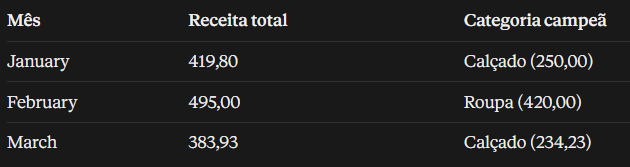

O ponto de atenção: como mes guarda nomes ("January", "February"...), o groupby ordena alfabeticamente, e a saída vem como February, January, March. Para uma análise ao longo do tempo, isso confunde. Duas saídas:

1. Criar mes como número: df["data"].dt.month (1, 2, 3), que ordena sozinho.
2. Usar df["data"].dt.to_period("M"), que mantém ano e mês e ordena cronologicamente (útil quando o dataset passa de um ano).

Outro detalhe: no .loc[campeao_por_mes] você passa uma Series de tuplas. Se algum dia der erro, use .loc[campeao_por_mes.tolist()], que é a forma mais segura.

Seus comentários explicam cada parte (MultiIndex, idxmax devolvendo o endereço e não o valor). Isso mostra que você entendeu o código, e não só que ele roda.

### 1. O padrão profissional para séries temporais: .dt.to_period("M")
Entre as duas opções para corrigir a ordenação alfabética (February antes de January), acostume-se a usar df["data"].dt.to_period("M") sempre que trabalhar com dados reais de vendas ou e-commerce:

- O .dt.month funciona em bases de um único ano, mas se você juntar vendas de janeiro de 2025 com janeiro de 2026, ele soma os dois anos juntos no mês 1.

- O .dt.to_period("M") gera rótulos como 2024-01, 2024-02, 2024-03, que mantêm o ano separado e ordenam cronologicamente de forma automática — inclusive nos gráficos do Matplotlib e Seaborn que você vai fazer no Dia 11.

### 2. Blindagem no .loc[...] com .tolist()

Passar campeao_por_mes.tolist() converte a Series do pandas em uma lista pura do Python ([('2024-01', 'Calçado'), ('2024-02', 'Roupa'), ...]). Isso garante que o .loc interprete cada tupla estritamente como uma coordenada de linha no MultiIndex, sem risco de tentar alinhar índices e lançar erro de KeyError dependendo da versão do pandas.

## O "mapa mental" para nunca mais confundir max(), idxmax() e .loc[]:
Imagine uma corrida onde você quer saber quem ganhou e qual foi o tempo:

- .max() responde: "Qual foi o maior valor?" -> Devolve só o número (420.0).

- .idxmax() responde: "Em qual linha/etiqueta está o maior valor?" -> Devolve o rótulo (('February', 'Roupa')).

- .loc[...] responde: "Agora que eu tenho as etiquetas dos vencedores, me mostre a linha inteira deles com nome e valor." -> Devolve February | Roupa | 420.00.

Com essa auditoria concluída, você tem o domínio completo de todo o pipeline do Dia 10! Você está pronto para salvar esse notebook no GitHub e partir para o Dia 11 (Matplotlib e Seaborn) — onde você vai pegar exatamente esses groupby que acabou de dominar e transformá-los em gráficos de barras e linhas.